**Trabajo Final Grupal**: AIRBNB Price - Machine Learning

**Universidad Tecnológica Nacional, Buenos Aires**
**Ingeniería Industrial**

**Ciencia de Datos - Curso I5571**


## 1. Importar librerías y dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# Usamos el dataset limpio del EDA.
df = pd.read_csv('airbnb_clean.csv')

# Convertimos la tasa de respuesta de texto ('90%') a número (90).
df['host_response_rate'] = pd.to_numeric(
    df['host_response_rate'].str.replace('%', '', regex=False), errors='coerce'
)

# La columna booleana se representa con 0 y 1.
df['cleaning_fee'] = df['cleaning_fee'].astype(int)

# Dejamos afuera dos variables difíciles de usar directamente:
# amenities (tiene casi una única combinación de amenities) y host_since (fecha que crearian muchas columnas). Podrían trabajarse en otro análisis.
df = df.drop(columns=['amenities', 'host_since'])

print('Filas y columnas:', df.shape)
print('Valores faltantes principales:')
print(df.isnull().sum().sort_values(ascending=False).head(8))

Filas y columnas: (19309, 20)
Valores faltantes principales:
host_response_rate        4296
review_scores_rating      4134
neighbourhood             1458
bathrooms                   35
beds                        24
bedrooms                    17
host_identity_verified       3
host_has_profile_pic         3
dtype: int64


## 2. Separar entrenamiento y prueba
Primero se divide el dataset. Los valores faltantes se completarán **después**, utilizando solo los datos de entrenamiento.

In [ ]:
# X = características para predecir; y = precio real a predecir.
X = df.drop(columns='price')
y = df['price']

# Dejamos el 20 % de las publicaciones para evaluar predicciones en datos no vistos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Separamos variables numéricas y categóricas porque se preparan de distintas maneras.
cols_numericas = X.select_dtypes(include='number').columns.tolist()
cols_categoricas = X.select_dtypes(include='object').columns.tolist()

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Numéricas:', cols_numericas)
print('Categóricas:', cols_categoricas)

Train: (15447, 19) | Test: (3862, 19)
Numéricas: ['accommodates', 'bathrooms', 'cleaning_fee', 'host_response_rate', 'latitude', 'longitude', 'number_of_reviews', 'review_scores_rating', 'bedrooms', 'beds']
Categóricas: ['property_type', 'room_type', 'bed_type', 'cancellation_policy', 'city', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable', 'neighbourhood']


## 3. Construir el preprocesamiento (Pipeline + ColumnTransformer)
- Numéricas: completar nulos con la mediana y estandarizar.
- Categóricas: completar nulos con la categoría más frecuente y generar columnas de tipo 0/1.

Todo se ajusta solo con `train`, incluso durante la validación cruzada.

In [ ]:
def crear_preprocesador():
    # Para variables numéricas: mediana para nulos y escalado para que sus magnitudes sean comparables.
    prep_numericas = Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler())
    ])

    # Para texto/categorías: categoría más frecuente para nulos y One-Hot Encoding.
    prep_categoricas = Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Aplicamos cada preparación a las columnas correspondientes.
    return ColumnTransformer([
        ('numericas', prep_numericas, cols_numericas),
        ('categoricas', prep_categoricas, cols_categoricas)
    ], sparse_threshold=0)  # Salida densa para permitir aplicar PCA después.


## 4. Regresión Ridge: elegir `alpha` con validación cruzada
La cátedra enseñó `GridSearchCV`: probamos varios niveles de regularización usando solo entrenamiento, sin tocar test. Usamos **3 folds** por practicidad.

In [ ]:
# Ridge es una regresión lineal con penalización para reducir el sobreajuste.
pipeline_ridge = Pipeline([
    ('preparacion', crear_preprocesador()),
    ('modelo', Ridge())
])

busqueda_ridge = GridSearchCV(
    pipeline_ridge,
    param_grid={'modelo__alpha': [1, 10, 100, 1000]},
    scoring='neg_root_mean_squared_error',  # Se maximiza el negativo del error (menor RMSE es mejor).
    cv=3,  # 3 particiones del train. No usamos datos de test.
    n_jobs=1
)
busqueda_ridge.fit(X_train, y_train)

mejor_alpha = busqueda_ridge.best_params_['modelo__alpha']
print('Mejor alpha:', mejor_alpha)
print('RMSE promedio en validación:', round(-busqueda_ridge.best_score_, 2), 'USD')

Mejor alpha: 10
RMSE promedio en validación: 156.37 USD


## 5. Entrenar y comparar cuatro enfoques
- **Referencia:** predecir siempre el promedio.
- **Lineal:** el modelo lineal básico.
- **Ridge:** compara si la regularización ayuda.
- **Random Forest:** intenta captar relaciones no lineales.
- **Ridge + PCA:** repetimos la regresión con menos dimensiones, como exige la consigna.

In [ ]:
# Creamos pipelines completos para que TODOS apliquen exactamente las mismas reglas.
modelos = {
    'Referencia (media)': DummyRegressor(strategy='mean'),
    'Regresion lineal': LinearRegression(),
    'Ridge': Ridge(alpha=mejor_alpha),
    # 60 árboles y profundidad moderada para que se ejecute rápido.
    'Random Forest': RandomForestRegressor(
        n_estimators=60, max_depth=16, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    )
}

resultados = []
predicciones = {}
pipelines = {}

for nombre, modelo in modelos.items():
    pipe = Pipeline([
        ('preparacion', crear_preprocesador()),
        ('modelo', modelo)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    # Mismas métricas y mismo test para que la comparación sea justa.
    resultados.append({
        'Modelo': nombre,
        'RMSE (USD)': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE (USD)': mean_absolute_error(y_test, pred),
        'R2': r2_score(y_test, pred)
    })
    predicciones[nombre] = pred
    pipelines[nombre] = pipe

print('Modelos entrenados:', list(modelos))

Modelos entrenados: ['Referencia (media)', 'Regresion lineal', 'Ridge', 'Random Forest']


## 6. Reducción de dimensionalidad: Ridge + PCA
PCA transforma las variables a nuevas componentes que explican la mayor parte de su variabilidad. Conservamos **95 % de la varianza** para probar si perder dimensiones afecta la calidad de la predicción.

In [ ]:
# PCA se ubica DENTRO del pipeline: se ajusta sobre train, nunca sobre test.
pipe_pca = Pipeline([
    ('preparacion', crear_preprocesador()),
    ('pca', PCA(n_components=0.95)),
    ('modelo', Ridge(alpha=mejor_alpha))
])

pipe_pca.fit(X_train, y_train)
pred_pca = pipe_pca.predict(X_test)

resultados.append({
    'Modelo': 'Ridge + PCA (95 %)',
    'RMSE (USD)': np.sqrt(mean_squared_error(y_test, pred_pca)),
    'MAE (USD)': mean_absolute_error(y_test, pred_pca),
    'R2': r2_score(y_test, pred_pca)
})
predicciones['Ridge + PCA (95 %)'] = pred_pca
pipelines['Ridge + PCA (95 %)'] = pipe_pca

print('Cantidad de componentes retenidas:', pipe_pca.named_steps['pca'].n_components_)
print('Varianza explicada acumulada:', round(pipe_pca.named_steps['pca'].explained_variance_ratio_.sum() * 100, 2), '%')

Cantidad de componentes retenidas: 35
Varianza explicada acumulada: 95.08 %


## 7. Resultados finales y gráficos
**RMSE** y **MAE** más bajos indican mejor predicción. **R²** más alto indica mejor capacidad para explicar diferencias de precios.

In [ ]:
tabla = pd.DataFrame(resultados).sort_values('RMSE (USD)')
print(tabla.round(2).to_string(index=False))

            Modelo  RMSE (USD)  MAE (USD)    R2
     Random Forest      156.73      76.73  0.47
             Ridge      170.52      94.26  0.37
  Regresion lineal      171.62      95.26  0.37
Ridge + PCA (95 %)      173.06      96.88  0.35
Referencia (media)      215.51     126.55 -0.00


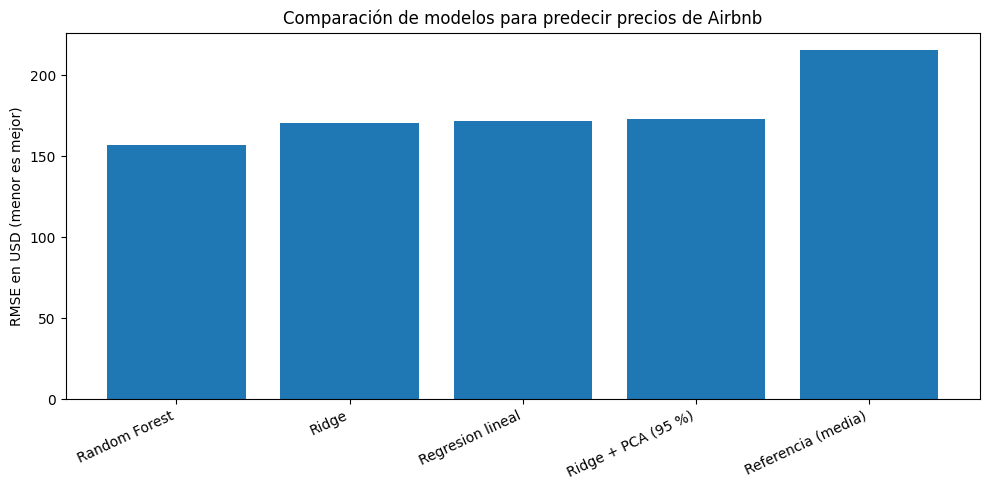

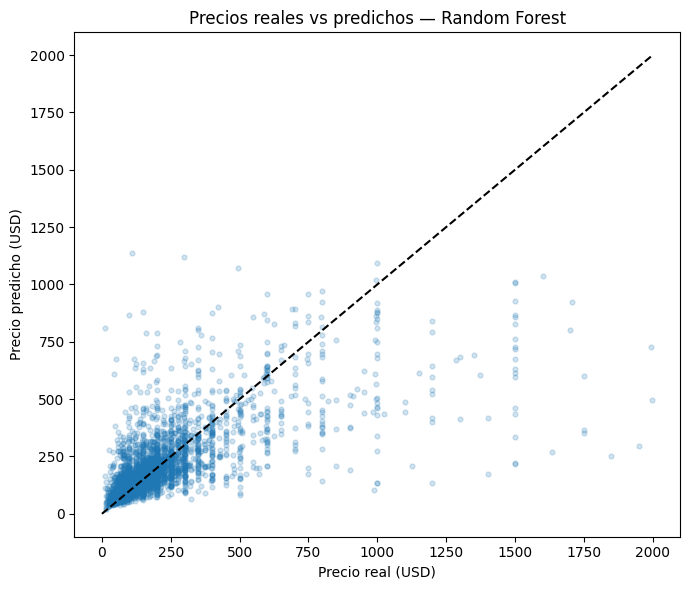

In [ ]:
# Gráfico 1: comparación de errores de todos los modelos.
plt.figure(figsize=(10, 5))
plt.bar(tabla['Modelo'], tabla['RMSE (USD)'])
plt.ylabel('RMSE en USD (menor es mejor)')
plt.title('Comparación de modelos para predecir precios de Airbnb')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

# Gráfico 2: cuánto se acercan las predicciones del mejor modelo a los precios reales.
mejor_nombre = tabla.iloc[0]['Modelo']
pred_mejor = predicciones[mejor_nombre]
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred_mejor, alpha=0.2, s=12)
limite = max(y_test.max(), pred_mejor.max())
plt.plot([0, limite], [0, limite], linestyle='--', color='black')
plt.xlabel('Precio real (USD)')
plt.ylabel('Precio predicho (USD)')
plt.title('Precios reales vs predichos — ' + mejor_nombre)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

# Comparamos los modelos usando validación cruzada.
# Dividimos el entrenamiento en 3 partes.
# Cada modelo se entrena y evalúa 3 veces con distintas particiones.

for nombre in ['Regresion lineal', 'Ridge', 'Random Forest']:

    scores = cross_val_score(
        pipelines[nombre],
        X_train,
        y_train,
        cv=3,
        scoring='neg_root_mean_squared_error',
        n_jobs=1
    )

    # Convertimos los puntajes negativos a RMSE positivos.
    rmse = -scores

    print(nombre)
    print("RMSE promedio:", round(rmse.mean(), 2))
    print("Desvío estándar:", round(rmse.std(), 2))
    print("-------------------------")

Regresion lineal
RMSE promedio: 158.2
Desvío estándar: 4.53
-------------------------
Ridge
RMSE promedio: 156.37
Desvío estándar: 3.76
-------------------------
Random Forest
RMSE promedio: 143.12
Desvío estándar: 4.27
-------------------------


## 8. Conclusiones

En este trabajo probamos distintos modelos de Machine Learning para predecir los precios de alojamientos de Airbnb: regresión lineal, Ridge y Random Forest.

### Comparación de modelos

Los resultados mostraron que **Random Forest fue el modelo que mejor funcionó**, con un RMSE de 156,73 USD y un R² de 0,47. La regresión lineal y Ridge tuvieron resultados similares, aunque con errores algo mayores.

Esto indica que Random Forest logró predecir mejor los precios, pero todavía tiene un margen importante de error, especialmente en las propiedades más caras.

### Validación cruzada

También realizamos una validación cruzada de tres particiones para comprobar si los resultados se mantenían al cambiar los datos de entrenamiento.

| Modelo           | RMSE promedio (USD) | Desvío estándar |
| ---------------- | ------------------: | --------------: |
| Regresión lineal |              158,20 |            4,53 |
| Ridge            |              156,37 |            3,76 |
| Random Forest    |          **143,12** |        **4,27** |

Los resultados fueron similares entre las distintas particiones y Random Forest volvió a obtener el menor error.

Esto nos da mayor confianza en que fue el mejor de los tres modelos evaluados.

### Reducción de dimensionalidad (PCA)

Aplicamos PCA para reducir la cantidad de variables, pasando a 35 componentes principales y conservando aproximadamente el 95 % de la variabilidad original.

Al volver a entrenar Ridge con estas componentes, el RMSE pasó de 170,52 a 173,06 USD.

Por lo tanto, **en nuestro caso PCA permitió reducir las dimensiones, pero no mejoró las predicciones**.

### Conclusión final

De los modelos que probamos, Random Forest fue el que obtuvo mejores resultados.

De todas formas, los errores siguen siendo considerables, por lo que entendemos que el modelo todavía podría mejorarse.

Como posibles mejoras, se podrían incorporar otras características de las propiedades, revisar el tratamiento de los precios más altos y probar diferentes configuraciones de los modelos.
